ملف تحميل الحزم (Packages)

In [1]:
# %matplotlib inline: Displays plots directly below cells
%matplotlib inline

# --- Core data libraries ---
import pandas as pd            # For loading and managing dataframes
import numpy as np             # For fast mathematical operations

# --- Visualization libraries ---
import matplotlib.pyplot as plt    # For basic charts and graphs
import seaborn as sns              # For advanced statistical plots

# --- Preprocessing (scikit-learn) ---
from sklearn.preprocessing import LabelEncoder, StandardScaler
# LabelEncoder   -> Converts text categories to numbers
# StandardScaler -> Normalizes numeric data (mean=0, std=1)

# --- Feature selection ---
from sklearn.feature_selection import SelectKBest, f_classif
# SelectKBest -> Ranks features by their correlation with the target

# --- Styling settings ---
sns.set_style("whitegrid")                 # Clean background for plots
plt.rcParams["figure.figsize"] = (10, 5)   # Default plot size
pd.set_option("display.width", 100)        # Console width for DataFrames
pd.set_option("display.max_columns", 20)   # Max columns to display

print("All packages loaded successfully.")

All packages loaded successfully.


ملف تحميل البيانات واستكشافها (Dataset & EDA)

In [2]:
# Load the dataset into a pandas DataFrame
DATA_PATH = "german_credit_data.csv"
dataset = pd.read_csv(DATA_PATH)

print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns")

Dataset loaded: 1000 rows, 10 columns


Descriptive statistics

In [3]:
# Display the first 5 rows
dataset.head()

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [4]:
# Check dataset dimensions
print("Shape (rows, columns):", dataset.shape)

Shape (rows, columns): (1000, 10)


In [5]:
# Check data types of all columns
dataset.dtypes

Age                int64
Sex                  str
Job                int64
Housing              str
SavingAccounts       str
CheckingAccount      str
CreditAmount       int64
Duration           int64
Purpose              str
Risk                 str
dtype: object

In [6]:
# Generate descriptive statistics for numeric columns
dataset.describe()

,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In [7]:
# Summary statistics for categorical columns
dataset.describe(exclude="number")

,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


In [ ]:
# Check for missing values per column
missing_counts = dataset.isna().sum()
print("Missing values per column:\n")
print(missing_counts)

Missing values per column:

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64


In [ ]:
# Analyze the target variable distribution (Risk)
print(dataset["Risk"].value_counts())
print()
print(dataset["Risk"].value_counts(normalize=True).round(3) * 100, "% of total")

Risk
good    700
bad     300
Name: count, dtype: int64

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64 % of total


Figure

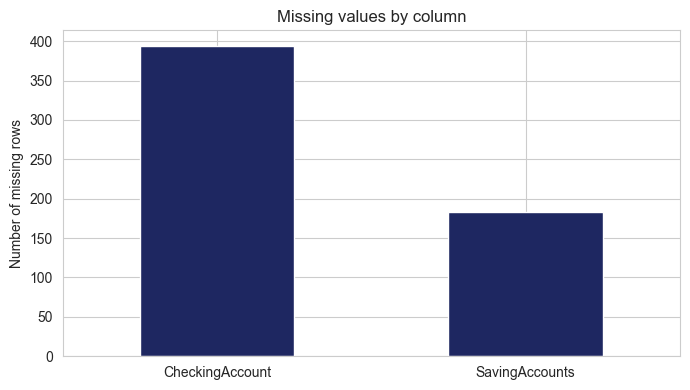

In [ ]:
# Plot missing values by column
missing_counts = dataset.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 4))
missing_counts.plot(kind="bar", color="#1E2761")
plt.title("Missing values by column")
plt.ylabel("Number of missing rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

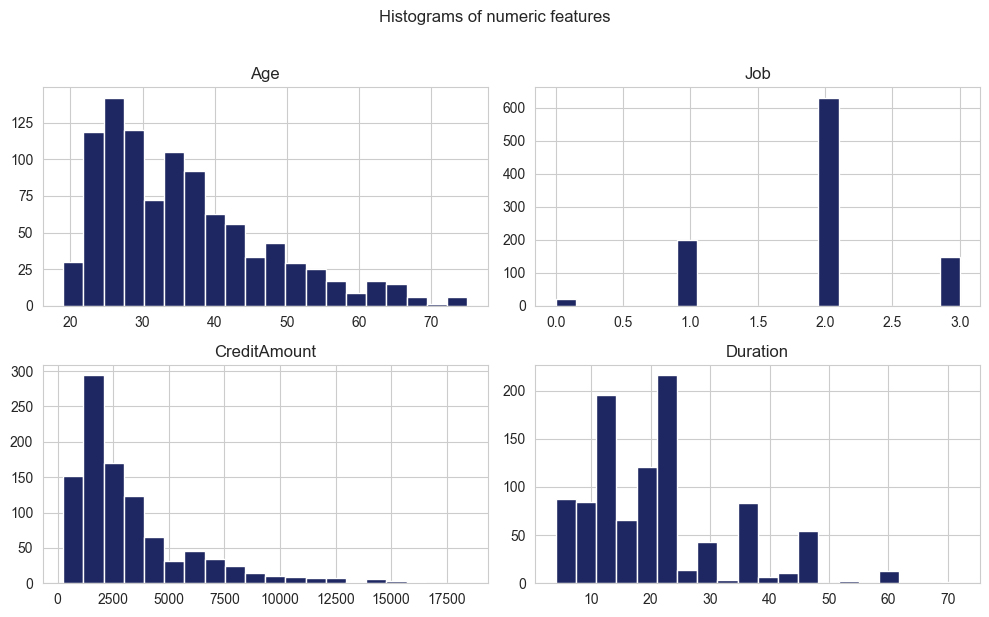

In [ ]:
# Plot histograms for numeric features
numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

dataset[numeric_cols].hist(figsize=(10, 6), bins=20, color="#1E2761", edgecolor="white")
plt.suptitle("Histograms of numeric features", y=1.02)
plt.tight_layout()
plt.show()

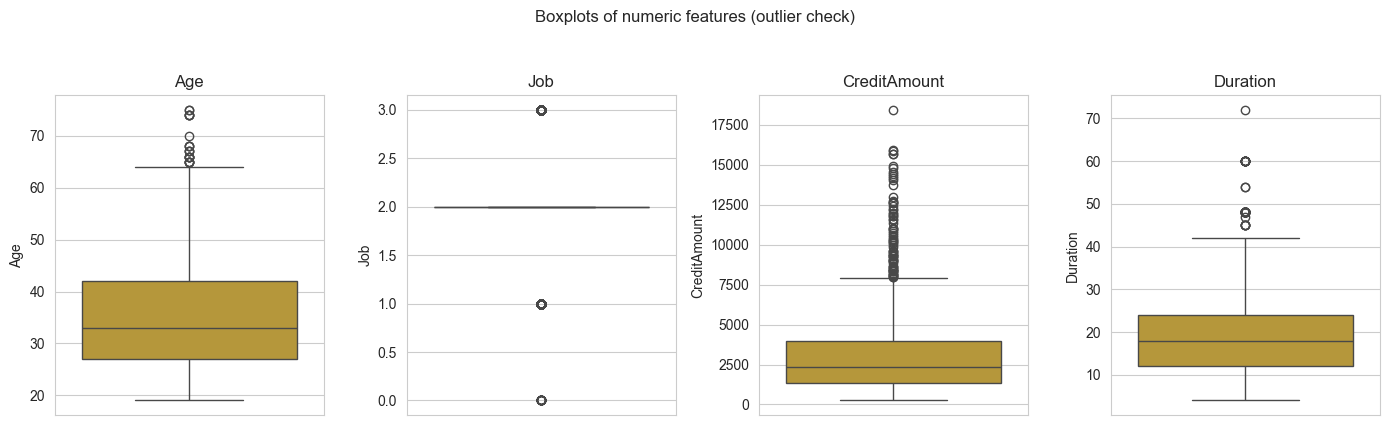

In [ ]:
# Plot boxplots to detect outliers in numeric features
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(14, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=dataset[col], ax=ax, color="#C9A227")
    ax.set_title(col)
plt.suptitle("Boxplots of numeric features (outlier check)", y=1.05)
plt.tight_layout()
plt.show()

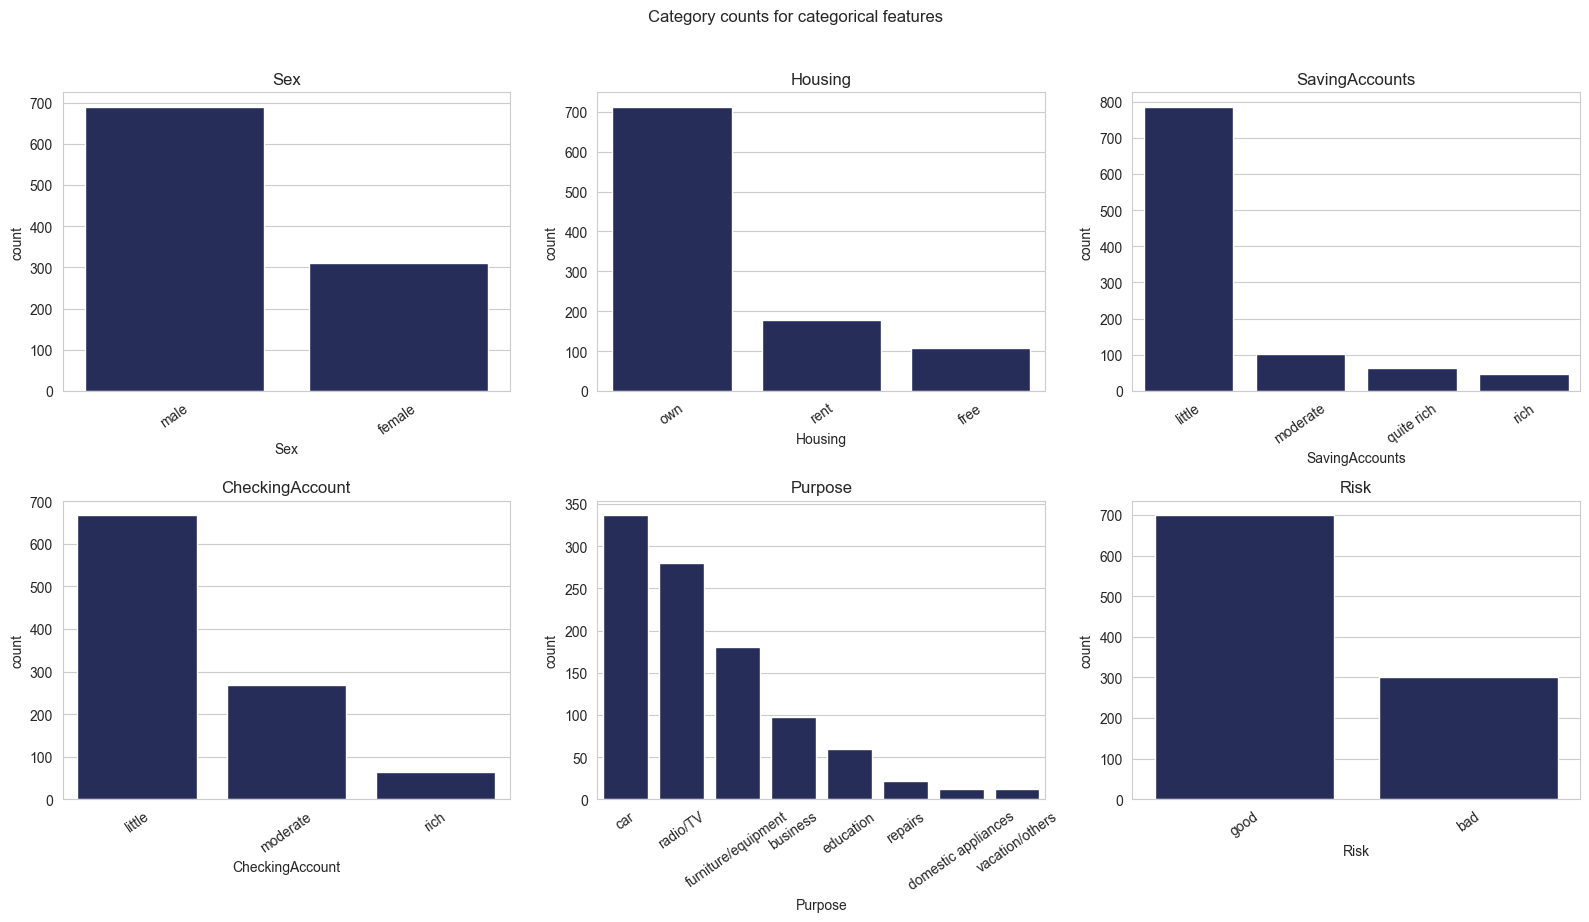

In [ ]:
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    col_data = dataset[col].fillna("Missing")  # Handle missing values
    order = col_data.value_counts().index      # Sort by frequency
    
    sns.countplot(x=col_data, order=order, ax=ax, color="#1E2761")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=35)

plt.suptitle("Category counts for categorical features", y=1.02)
plt.tight_layout()
plt.show()

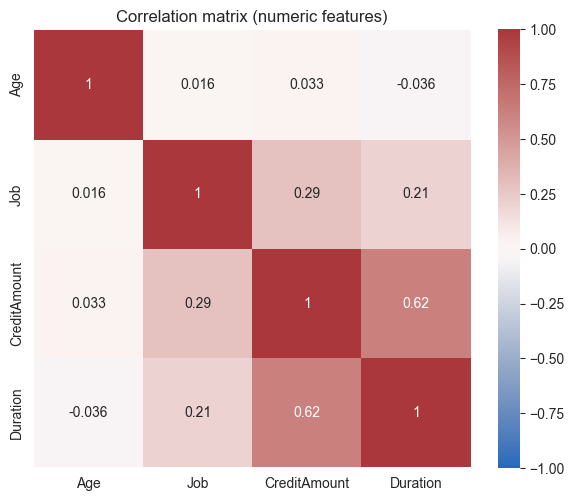

In [ ]:
plt.figure(figsize=(6, 5))
correlation = dataset[numeric_cols].corr()  # Calculate correlation matrix

sns.heatmap(correlation, vmin=-1, vmax=1, annot=True, cmap="vlag", square=True)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()

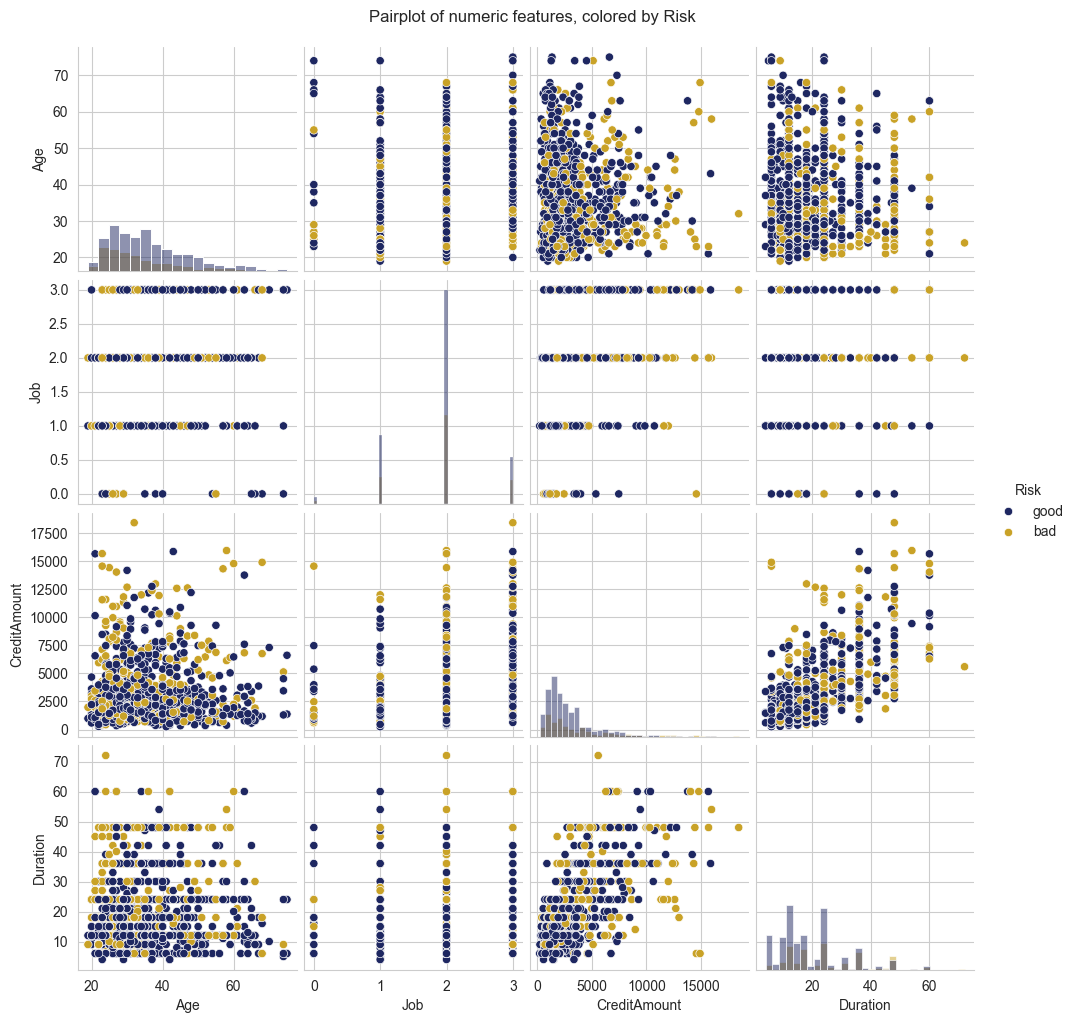

In [ ]:
# Pairplot of numeric features colored by Risk
sns.pairplot(dataset, vars=numeric_cols, hue="Risk", palette={"good": "#1E2761", "bad": "#C9A227"}, diag_kind="hist")
plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)
plt.show()

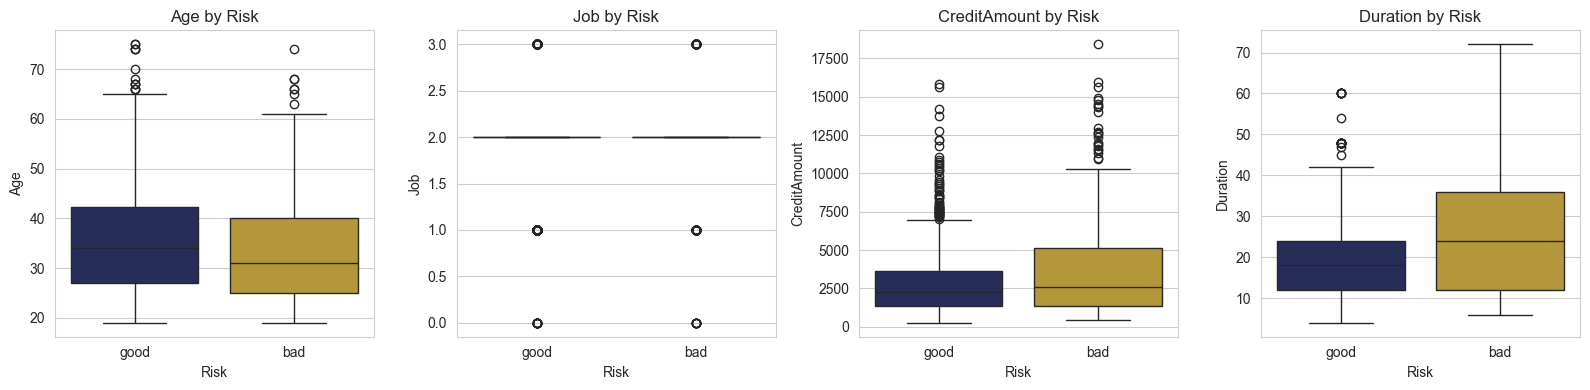

In [ ]:
# Boxplots grouped by Risk
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=dataset, x="Risk", y=col, hue="Risk",
                palette={"good": "#1E2761", "bad": "#C9A227"}, legend=False, ax=ax)
    ax.set_title(f"{col} by Risk")
plt.tight_layout()
plt.show()

# 'bad' risk applicants tend to have higher CreditAmount and Duration.

Data Preparation

In [ ]:
df_clean = dataset.copy()  # Work on a copy

# Fill missing values with "none" to preserve data
df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")

# Check remaining missing values
print("Remaining missing values:\n")
print(df_clean.isna().sum())

Remaining missing values:

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


Data transformation — encoding & scaling

In [ ]:
# Encode categorical columns
df_encoded = df_clean.copy()
categorical_cols_all = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

encoders = {}  # Store encoders for later decoding
for col in categorical_cols_all:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_clean[col])
    encoders[col] = le
    print(f"{col:16s} -> {list(le.classes_)}")

Sex              -> ['female', 'male']
Housing          -> ['free', 'own', 'rent']
SavingAccounts   -> ['little', 'moderate', 'quite rich', 'rich']
CheckingAccount  -> ['little', 'moderate', 'rich']
Purpose          -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk             -> ['bad', 'good']


In [ ]:
# Scale numeric columns (mean=0, std=1)
scaler = StandardScaler()
numeric_cols_to_scale = ["Age", "Job", "CreditAmount", "Duration"]

df_scaled = df_encoded.copy()
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_encoded[numeric_cols_to_scale])

# Compare before vs. after scaling
print("Before scaling:")
print(df_encoded[numeric_cols_to_scale].head(3))
print("\nAfter scaling:")
print(df_scaled[numeric_cols_to_scale].head(3).round(3))

Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling:
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739


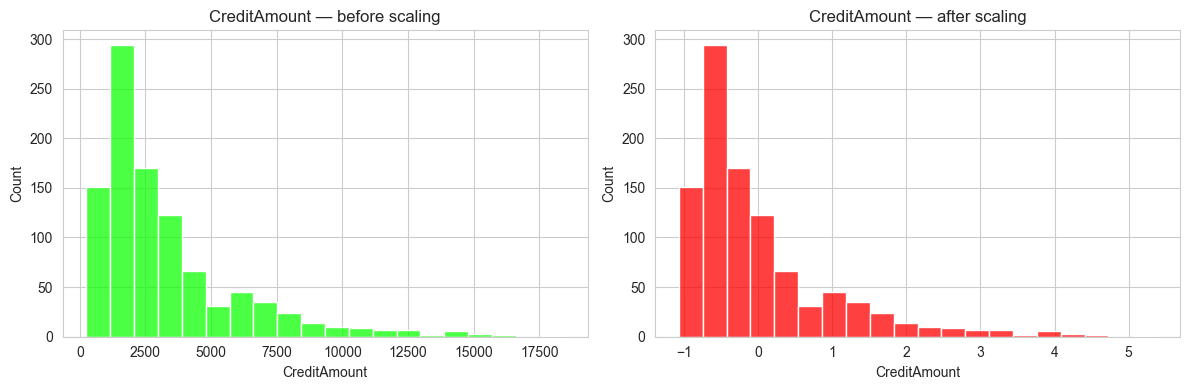

In [ ]:
# Visual check: scaling changes axis, not shape
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_encoded["CreditAmount"], bins=20, ax=axes[0], color="#0FFF06")
axes[0].set_title("CreditAmount — before scaling")
sns.histplot(df_scaled["CreditAmount"], bins=20, ax=axes[1], color="#FF0000")
axes[1].set_title("CreditAmount — after scaling")
plt.tight_layout()
plt.show()

In [ ]:
# Separate features (X) and target (y)
X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]

# Score features using SelectKBest (ANOVA F-test)
selector = SelectKBest(score_func=f_classif, k="all")  # Score all features
selector.fit(X, y)

feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
}).sort_values("Score", ascending=False).reset_index(drop=True)

feature_scores

,Feature,Score
0,Duration,48.333790
1,CreditAmount,24.482366
2,SavingAccounts,10.649045
3,Age,8.356995
4,Sex,5.720350
5,Purpose,3.745234
6,CheckingAccount,2.745220
7,Job,1.070584
8,Housing,0.372463


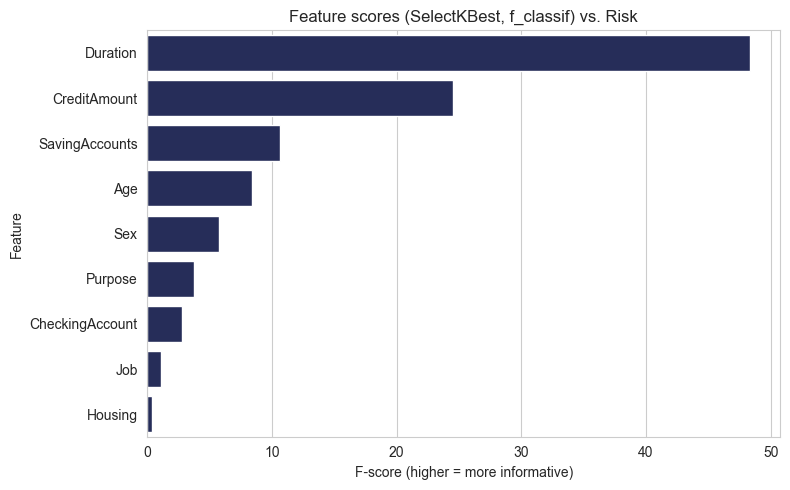

In [ ]:
# Bar chart of feature scores vs. Risk
plt.figure(figsize=(8, 5))
sns.barplot(data=feature_scores, x="Score", y="Feature", color="#1E2761")
plt.title("Feature scores (SelectKBest, f_classif) vs. Risk")
plt.xlabel("F-score (higher = more informative)")
plt.tight_layout()
plt.show()

# Ranking is a preprocessing step, not a trained model.